# 03 · Advanced Statistical Analysis & Hypothesis Testing
**Dataset:** UCI Wine Recognition data (178 wines, 3 cultivars, 13 chemical measurements) — a scientific dataset bundled with scikit-learn, so no download is needed.

**Workflow**
1. Load & inspect the data
2. Normality testing — Shapiro-Wilk and Kolmogorov-Smirnov (Lilliefors-corrected)
3. Two-sample tests — Welch's t-test vs Mann-Whitney U
4. One-Way ANOVA + Tukey HSD post-hoc (with Kruskal-Wallis as a robustness check)
5. Two-Way ANOVA (cultivar × alcohol level) + interaction plot
6. Confidence intervals and a summary of findings

All tests use a significance level of **α = 0.05**.

## 1 · Setup & data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_wine

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

ALPHA = 0.05
RNG = np.random.default_rng(42)          # reproducible Monte-Carlo
VARS = ["alcohol", "flavanoids", "proline", "color_intensity"]
ORDER = ["Cultivar A", "Cultivar B", "Cultivar C"]

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["cultivar"] = df["target"].map({0: "Cultivar A", 1: "Cultivar B", 2: "Cultivar C"})
df = df.drop(columns="target")

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print()
print(df.head().to_string())
print()
print(df["cultivar"].value_counts().reindex(ORDER).to_string())

Shape: (178, 14)
Missing values: 0

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  od280/od315_of_diluted_wines  proline    cultivar
0    14.23        1.71  2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64  1.04                          3.92   1065.0  Cultivar A
1    13.20        1.78  2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38  1.05                          3.40   1050.0  Cultivar A
2    13.16        2.36  2.67               18.6      101.0           2.80        3.24                  0.30             2.81             5.68  1.03                          3.17   1185.0  Cultivar A
3    14.37        1.95  2.50               16.8      113.0           3.85        3.49                  0.24             2.18             7.80  0.86                     

In [3]:
summary = df.groupby("cultivar")[VARS].agg(["count", "mean", "std"]).round(2)
print(summary.T.to_string())

cultivar               Cultivar A  Cultivar B  Cultivar C
alcohol         count       59.00       71.00       48.00
                mean        13.74       12.28       13.15
                std          0.46        0.54        0.53
flavanoids      count       59.00       71.00       48.00
                mean         2.98        2.08        0.78
                std          0.40        0.71        0.29
proline         count       59.00       71.00       48.00
                mean      1115.71      519.51      629.90
                std        221.52      157.21      115.10
color_intensity count       59.00       71.00       48.00
                mean         5.53        3.09        7.40
                std          1.24        0.92        2.31


## 2 · Normality tests (Shapiro-Wilk & Kolmogorov-Smirnov)

For every variable and cultivar:

- **H₀:** the sample comes from a normal distribution
- **H₁:** the sample does **not** come from a normal distribution
- Reject H₀ if p < 0.05.

> **Note on K-S:** because the mean and SD are *estimated from the sample*, the standard K-S p-value is too conservative. We therefore compute the **Lilliefors-corrected** p-value by Monte-Carlo simulation (2,000 simulated normal samples per test).

In [4]:
def ks_stat(z):
    z = np.sort(z); n = len(z)
    cdf = stats.norm.cdf(z); i = np.arange(1, n + 1)
    return max(np.max(i / n - cdf), np.max(cdf - (i - 1) / n))

def ks_lilliefors(x, n_sim=2000):
    x = np.asarray(x, float)
    d = ks_stat((x - x.mean()) / x.std(ddof=1))
    sims = np.empty(n_sim)
    for k in range(n_sim):
        s = RNG.standard_normal(len(x))
        sims[k] = ks_stat((s - s.mean()) / s.std(ddof=1))
    return d, (np.sum(sims >= d) + 1) / (n_sim + 1)

rows = []
for var in VARS:
    for g in ORDER:
        x = df.loc[df.cultivar == g, var].values
        W, p_sw = stats.shapiro(x)
        D, p_ks = ks_lilliefors(x)
        rows.append(dict(variable=var, group=g, n=len(x),
                         shapiro_W=W, shapiro_p=p_sw, ks_D=D, ks_p=p_ks,
                         normal=(p_sw > ALPHA) and (p_ks > ALPHA)))
norm_tbl = pd.DataFrame(rows)
print(norm_tbl.round(4).to_string(index=False))

       variable      group  n  shapiro_W  shapiro_p   ks_D   ks_p  normal
        alcohol Cultivar A 59     0.9809     0.4791 0.0694 0.6872    True
        alcohol Cultivar B 71     0.9721     0.1140 0.1076 0.0480   False
        alcohol Cultivar C 48     0.9815     0.6408 0.0930 0.3523    True
     flavanoids Cultivar A 59     0.9842     0.6387 0.0756 0.5302    True
     flavanoids Cultivar B 71     0.9372     0.0015 0.1159 0.0190   False
     flavanoids Cultivar C 48     0.8922     0.0004 0.1718 0.0010   False
        proline Cultivar A 59     0.9819     0.5232 0.0651 0.7786    True
        proline Cultivar B 71     0.9387     0.0018 0.1326 0.0050   False
        proline Cultivar C 48     0.9769     0.4585 0.0631 0.9000    True
color_intensity Cultivar A 59     0.9682     0.1251 0.0730 0.6047    True
color_intensity Cultivar B 71     0.9317     0.0008 0.1420 0.0005   False
color_intensity Cultivar C 48     0.9585     0.0878 0.1435 0.0185   False


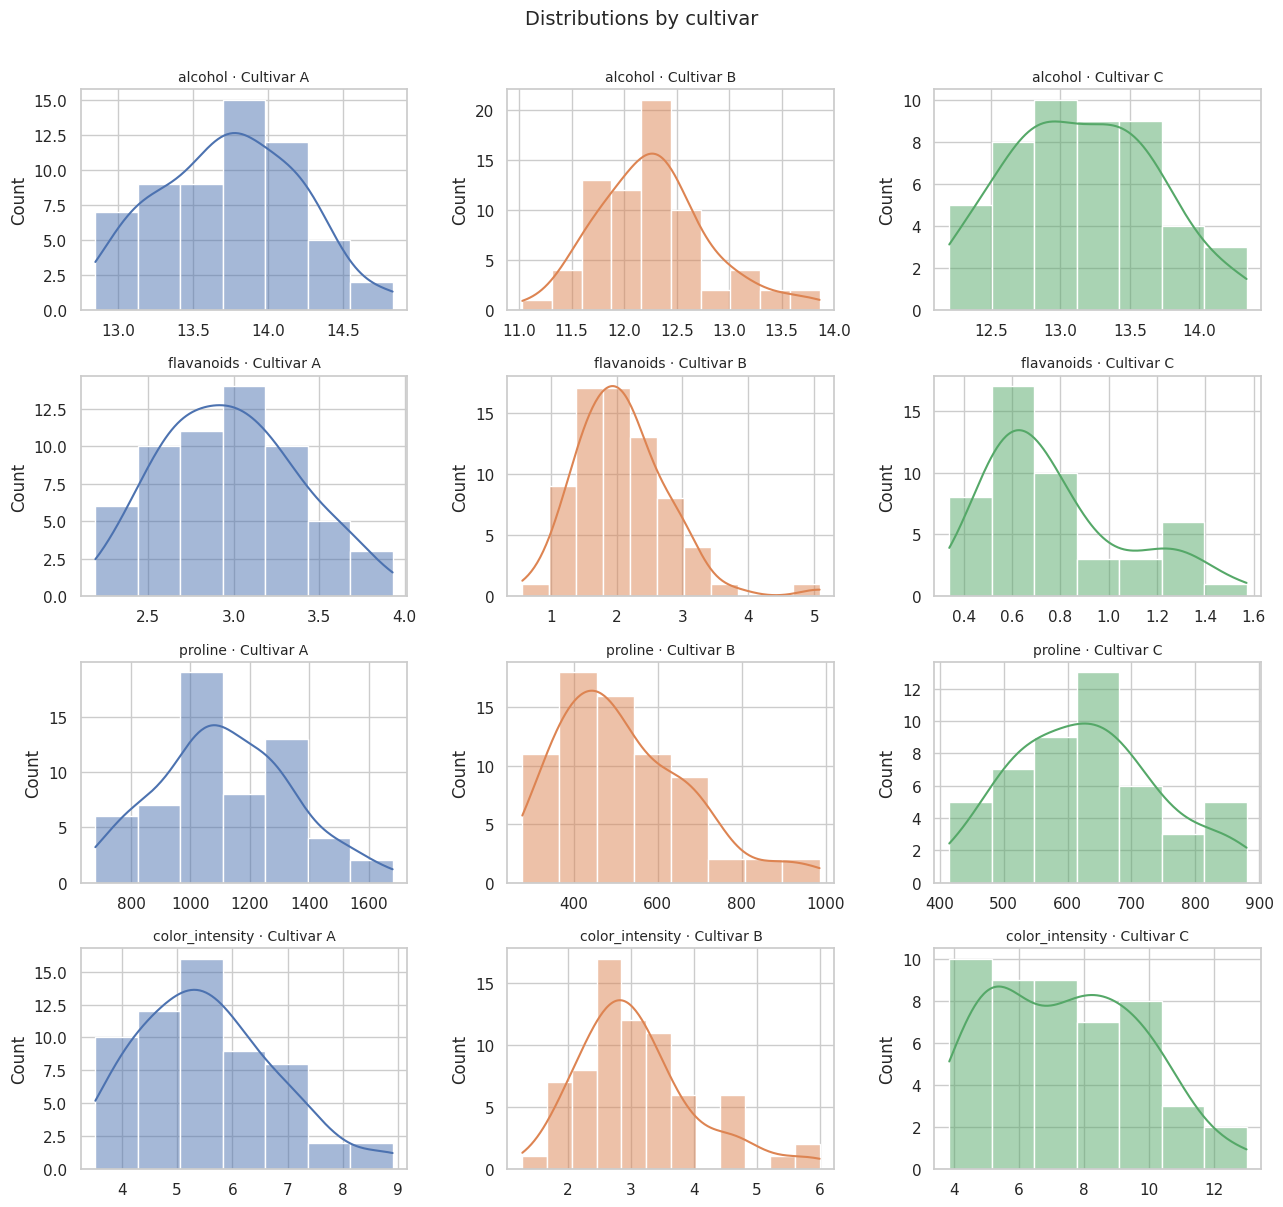

In [5]:
fig, axes = plt.subplots(len(VARS), 3, figsize=(13, 12))
for r, var in enumerate(VARS):
    for c, g in enumerate(ORDER):
        x = df.loc[df.cultivar == g, var]
        sns.histplot(x, kde=True, ax=axes[r, c], color=sns.color_palette()[c], edgecolor="white")
        axes[r, c].set_title(f"{var} · {g}", fontsize=10)
        axes[r, c].set_xlabel("")
plt.suptitle("Distributions by cultivar", y=1.005, fontsize=14)
plt.tight_layout(); plt.show()

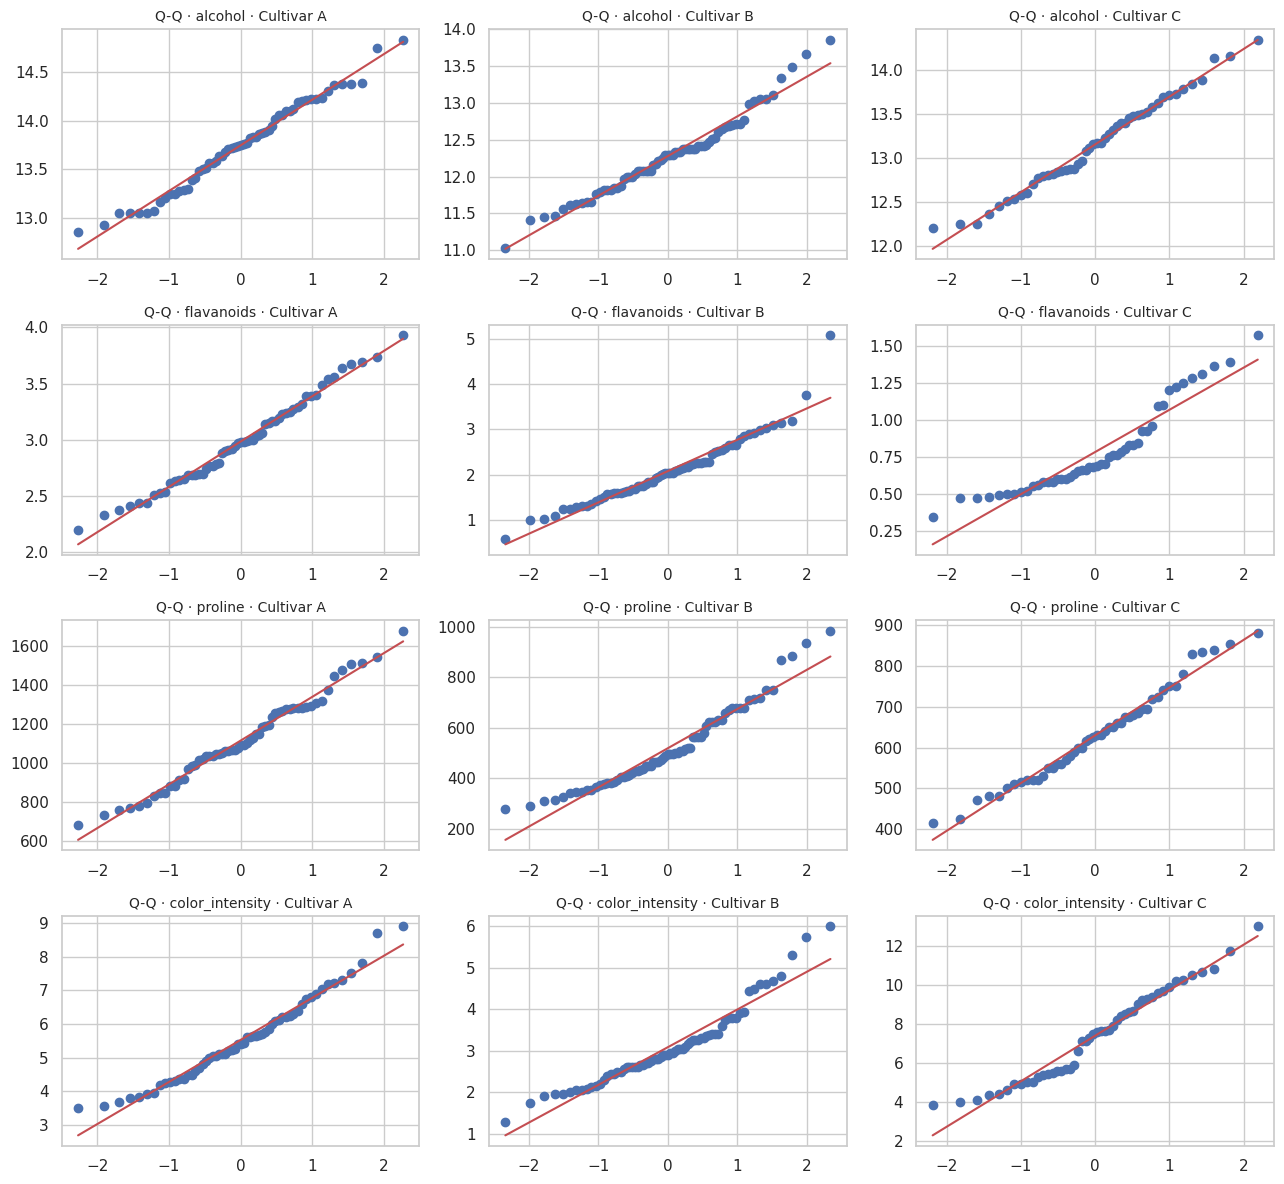

In [6]:
fig, axes = plt.subplots(len(VARS), 3, figsize=(13, 12))
for r, var in enumerate(VARS):
    for c, g in enumerate(ORDER):
        stats.probplot(df.loc[df.cultivar == g, var], dist="norm", plot=axes[r, c])
        axes[r, c].set_title(f"Q-Q · {var} · {g}", fontsize=10)
        axes[r, c].set_xlabel(""); axes[r, c].set_ylabel("")
plt.tight_layout(); plt.show()

## 3 · Two-sample tests: Cultivar A vs Cultivar B

For each variable:

| | Parametric | Non-parametric |
|---|---|---|
| **Test** | Welch's two-sample t-test | Mann-Whitney U |
| **H₀** | μ_A = μ_B | The two distributions are equal (no stochastic dominance) |
| **H₁** | μ_A ≠ μ_B | The distributions differ |

Welch's version is used (does not assume equal variances). Levene's test is reported for reference. Effect size is Cohen's *d* and we report the 95 % CI of the mean difference.

In [7]:
def welch_ci(a, b, conf=0.95):
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    diff = a.mean() - b.mean()
    t = stats.t.ppf(1 - (1 - conf) / 2, dof)
    return diff, diff - t * se, diff + t * se

def cohens_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

rows = []
for var in VARS:
    a = df.loc[df.cultivar == "Cultivar A", var]
    b = df.loc[df.cultivar == "Cultivar B", var]
    both_normal = bool(norm_tbl[(norm_tbl.variable == var) &
                                (norm_tbl.group.isin(["Cultivar A", "Cultivar B"]))].normal.all())
    lev_p = stats.levene(a, b).pvalue
    t, p_t = stats.ttest_ind(a, b, equal_var=False)
    U, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
    diff, lo, hi = welch_ci(a, b)
    rows.append(dict(variable=var, both_normal=both_normal, levene_p=lev_p,
                     t=t, t_p=p_t, U=U, U_p=p_u,
                     mean_diff=diff, ci95_low=lo, ci95_high=hi, cohens_d=cohens_d(a, b),
                     recommended="t-test" if both_normal else "Mann-Whitney U"))
two_tbl = pd.DataFrame(rows)
print(two_tbl.round(4).to_string(index=False))
print()
for _, r in two_tbl.iterrows():
    p = r.t_p if r.recommended == "t-test" else r.U_p
    verdict = "REJECT H0" if p < ALPHA else "fail to reject H0"
    print(f"{r.variable:<16} {r.recommended:<15} p = {p:.4g}  ->  {verdict}")

       variable  both_normal  levene_p       t  t_p      U  U_p  mean_diff  ci95_low  ci95_high  cohens_d    recommended
        alcohol        False    0.5771 16.7113  0.0 4079.5  0.0     1.4660    1.2924     1.6396    2.9029 Mann-Whitney U
     flavanoids        False    0.0045  9.1573  0.0 3709.5  0.0     0.9015    0.7065     1.0966    1.5372 Mann-Whitney U
        proline        False    0.0108 17.3575  0.0 4133.0  0.0   596.2048  528.0740   664.3357    3.1532 Mann-Whitney U
color_intensity        False    0.0166 12.5173  0.0 3966.0  0.0     2.4417    2.0549     2.8284    2.2642 Mann-Whitney U

alcohol          Mann-Whitney U  p = 1.67e-20  ->  REJECT H0
flavanoids       Mann-Whitney U  p = 4.344e-14  ->  REJECT H0
proline          Mann-Whitney U  p = 1.56e-21  ->  REJECT H0
color_intensity  Mann-Whitney U  p = 2.133e-18  ->  REJECT H0


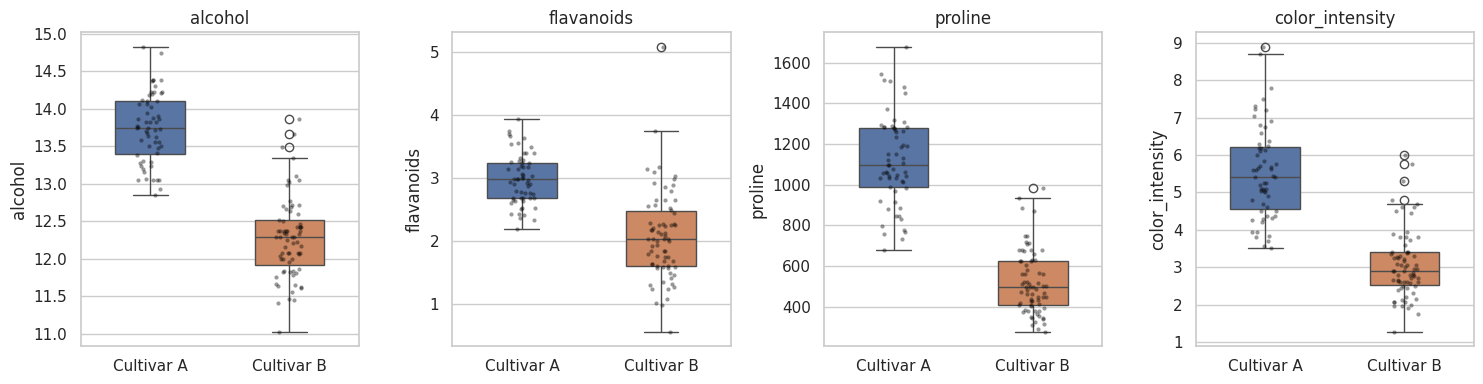

In [8]:
fig, axes = plt.subplots(1, len(VARS), figsize=(15, 4))
sub = df[df.cultivar.isin(["Cultivar A", "Cultivar B"])]
for ax, var in zip(axes, VARS):
    sns.boxplot(data=sub, x="cultivar", y=var, hue="cultivar", ax=ax, width=0.5, legend=False)
    sns.stripplot(data=sub, x="cultivar", y=var, ax=ax, color="black", alpha=0.4, size=3)
    ax.set_title(var); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 4 · One-Way ANOVA with Tukey HSD

For each variable across the three cultivars:

- **H₀:** μ_A = μ_B = μ_C
- **H₁:** at least one cultivar mean differs
- Assumptions checked with Levene's test (equal variances) and Shapiro-Wilk on the ANOVA residuals. **Kruskal-Wallis** is run as a non-parametric cross-check.
- If ANOVA is significant, **Tukey HSD** identifies which pairs differ (H₀: the two means are equal; family-wise α = 0.05).
- Effect size: η² = SS_between / SS_total.

In [9]:
rows = []
for var in VARS:
    groups = [df.loc[df.cultivar == g, var].values for g in ORDER]
    resid = np.concatenate([g - g.mean() for g in groups])
    F, p_f = stats.f_oneway(*groups)
    H, p_h = stats.kruskal(*groups)
    grand = np.concatenate(groups).mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    sst = ((np.concatenate(groups) - grand) ** 2).sum()
    rows.append(dict(variable=var, levene_p=stats.levene(*groups).pvalue,
                     resid_shapiro_p=stats.shapiro(resid).pvalue,
                     F=F, anova_p=p_f, eta_sq=ssb / sst, kruskal_H=H, kruskal_p=p_h))
anova1 = pd.DataFrame(rows)
print(anova1.round(5).to_string(index=False))

       variable  levene_p  resid_shapiro_p         F  anova_p  eta_sq  kruskal_H  kruskal_p
        alcohol   0.55005          0.24590 135.07762      0.0 0.60688  109.51042        0.0
     flavanoids   0.00002          0.00000 233.92587      0.0 0.72778  130.45243        0.0
        proline   0.00030          0.02104 207.92037      0.0 0.70381  119.05985        0.0
color_intensity   0.00000          0.01103 120.66402      0.0 0.57966  115.04978        0.0


In [10]:
rows = []
for var in VARS:
    groups = [df.loc[df.cultivar == g, var].values for g in ORDER]
    res = stats.tukey_hsd(*groups)
    ci = res.confidence_interval(0.95)
    for i in range(3):
        for j in range(i + 1, 3):
            rows.append(dict(variable=var, pair=f"{ORDER[i][-1]} - {ORDER[j][-1]}",
                             mean_diff=groups[i].mean() - groups[j].mean(),
                             ci95_low=ci.low[i, j], ci95_high=ci.high[i, j],
                             p_adj=res.pvalue[i, j],
                             significant=res.pvalue[i, j] < ALPHA))
tukey = pd.DataFrame(rows)
print(tukey.round(4).to_string(index=False))

       variable  pair  mean_diff  ci95_low  ci95_high  p_adj  significant
        alcohol A - B     1.4660    1.2528     1.6792 0.0000         True
        alcohol A - C     0.5910    0.3558     0.8262 0.0000         True
        alcohol B - C    -0.8750   -1.1011    -0.6489 0.0000         True
     flavanoids A - B     0.9015    0.6833     1.1198 0.0000         True
     flavanoids A - C     2.2009    1.9601     2.4417 0.0000         True
     flavanoids B - C     1.2994    1.0679     1.5309 0.0000         True
        proline A - B   596.2048  524.4309   667.9787 0.0000         True
        proline A - C   485.8160  406.6215   565.0106 0.0000         True
        proline B - C  -110.3888 -186.5219   -34.2556 0.0022         True
color_intensity A - B     2.4417    1.8122     3.0711 0.0000         True
color_intensity A - C    -1.8679   -2.5625    -1.1734 0.0000         True
color_intensity B - C    -4.3096   -4.9773    -3.6419 0.0000         True


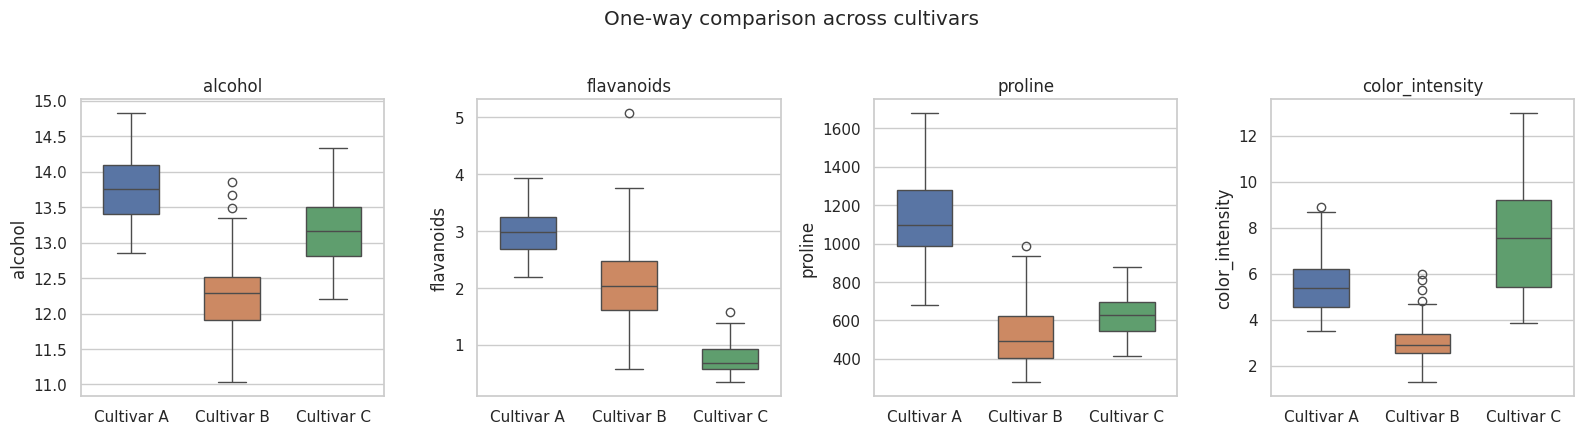

In [11]:
fig, axes = plt.subplots(1, len(VARS), figsize=(16, 4.2))
for ax, var in zip(axes, VARS):
    sns.boxplot(data=df, x="cultivar", y=var, hue="cultivar", order=ORDER, hue_order=ORDER,
                ax=ax, width=0.55, legend=False)
    ax.set_title(var); ax.set_xlabel("")
plt.suptitle("One-way comparison across cultivars", y=1.03)
plt.tight_layout(); plt.show()

## 5 · Two-Way ANOVA: Cultivar × Alcohol level

To get a second factor, wines are split into **Low / High alcohol** at the overall median. The response is **flavanoids**.

| Effect | H₀ | H₁ |
|---|---|---|
| Cultivar (main) | Mean flavanoids equal across cultivars | At least one cultivar differs |
| Alcohol level (main) | Mean flavanoids equal for Low and High alcohol | They differ |
| Cultivar × Alcohol (interaction) | Effect of alcohol level is the same for every cultivar | The effect depends on the cultivar |

`statsmodels` is not required: the ANOVA table (**Type III** sums of squares with sum-to-zero coding, so it is valid for unbalanced cells) is computed directly with NumPy/SciPy.

In [12]:
df["alcohol_level"] = np.where(df["alcohol"] > df["alcohol"].median(), "High", "Low")
RESP = "flavanoids"
print("Cell sizes (n per cell):")
print(pd.crosstab(df.cultivar, df.alcohol_level).to_string())
print()
print("Cell means of", RESP)
print(df.pivot_table(index="cultivar", columns="alcohol_level", values=RESP, aggfunc="mean").round(3).to_string())

Cell sizes (n per cell):
alcohol_level  High  Low
cultivar                
Cultivar A       53    6
Cultivar B        5   66
Cultivar C       27   21

Cell means of flavanoids
alcohol_level   High    Low
cultivar                   
Cultivar A     3.015  2.693
Cultivar B     2.194  2.072
Cultivar C     0.797  0.762


In [13]:
def effect_coding(series, levels):
    cols = []
    for lv in levels[:-1]:
        cols.append(np.where(series == lv, 1.0, np.where(series == levels[-1], -1.0, 0.0)))
    return np.column_stack(cols)

def two_way_anova(data, y, a, b, a_levels, b_levels):
    yv = data[y].values.astype(float)
    A = effect_coding(data[a].values, a_levels)
    B = effect_coding(data[b].values, b_levels)
    AB = np.column_stack([A[:, i] * B[:, j] for i in range(A.shape[1]) for j in range(B.shape[1])])
    ones = np.ones((len(yv), 1))
    blocks = {"Intercept": ones, a: A, b: B, f"{a}:{b}": AB}

    def sse(names):
        X = np.hstack([blocks[n] for n in names])
        beta, *_ = np.linalg.lstsq(X, yv, rcond=None)
        r = yv - X @ beta
        return float(r @ r), X.shape[1]

    names = list(blocks)
    sse_full, k_full = sse(names)
    df_res = len(yv) - k_full
    ms_res = sse_full / df_res
    rows = []
    for term in names[1:]:
        reduced = [n for n in names if n != term]
        sse_red, _ = sse(reduced)
        ss = sse_red - sse_full
        dfn = blocks[term].shape[1]
        F = (ss / dfn) / ms_res
        rows.append(dict(source=term, sum_sq=ss, df=dfn, mean_sq=ss / dfn, F=F,
                         p_value=stats.f.sf(F, dfn, df_res), partial_eta_sq=ss / (ss + sse_full)))
    rows.append(dict(source="Residual", sum_sq=sse_full, df=df_res, mean_sq=ms_res,
                     F=np.nan, p_value=np.nan, partial_eta_sq=np.nan))
    return pd.DataFrame(rows)

anova2 = two_way_anova(df, RESP, "cultivar", "alcohol_level", ORDER, ["High", "Low"])
print(anova2.round(5).to_string(index=False))

                source   sum_sq  df  mean_sq         F  p_value  partial_eta_sq
              cultivar 70.98639   2 35.49319 128.70518  0.00000         0.59945
         alcohol_level  0.47126   1  0.47126   1.70889  0.19287         0.00984
cultivar:alcohol_level  0.30489   2  0.15244   0.55279  0.57636         0.00639
              Residual 47.43266 172  0.27577       NaN      NaN             NaN


In [14]:
# Assumption checks on the two-way model
df["cell"] = df["cultivar"] + " | " + df["alcohol_level"]
cell_mean = df.groupby("cell")[RESP].transform("mean")
resid2 = df[RESP] - cell_mean
print("Shapiro-Wilk on residuals: W = %.4f, p = %.4f" % stats.shapiro(resid2))
print("Levene across the 6 cells:  stat = %.4f, p = %.4f" %
      (lambda r: (r.statistic, r.pvalue))(stats.levene(*[g[RESP].values for _, g in df.groupby("cell")])))

Shapiro-Wilk on residuals: W = 0.9294, p = 0.0000
Levene across the 6 cells:  stat = 4.5501, p = 0.0006


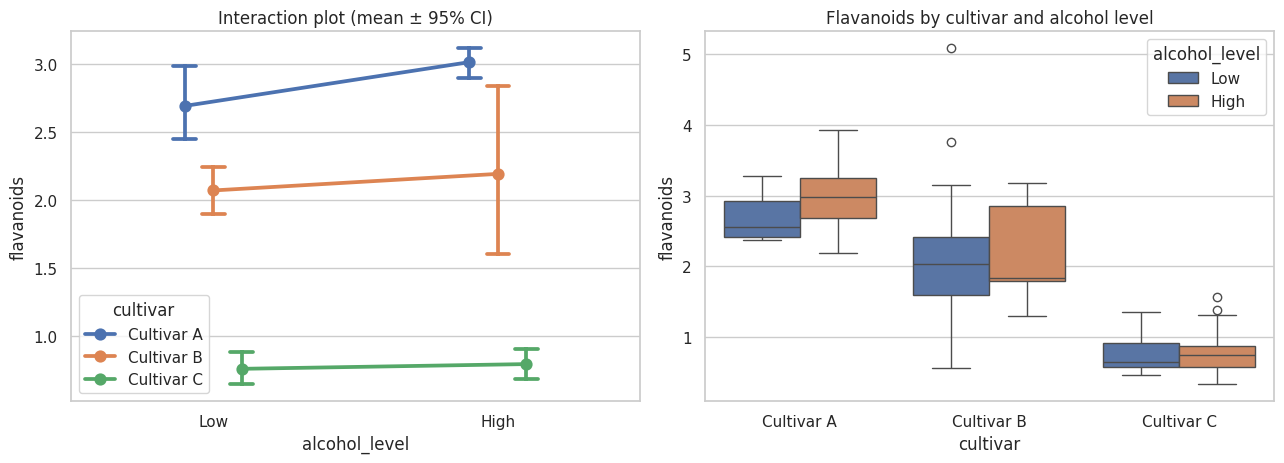

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.pointplot(data=df, x="alcohol_level", y=RESP, hue="cultivar", hue_order=ORDER,
              order=["Low", "High"], errorbar=("ci", 95), dodge=0.2, capsize=0.08, ax=axes[0])
axes[0].set_title("Interaction plot (mean ± 95% CI)")
sns.boxplot(data=df, x="cultivar", y=RESP, hue="alcohol_level", order=ORDER,
            hue_order=["Low", "High"], ax=axes[1])
axes[1].set_title("Flavanoids by cultivar and alcohol level")
plt.tight_layout(); plt.show()

In [16]:
# Tukey HSD across the 6 cells (post-hoc for the two-way design)
cells = sorted(df["cell"].unique())
cell_data = [df.loc[df.cell == c, RESP].values for c in cells]
res = stats.tukey_hsd(*cell_data)
ci = res.confidence_interval(0.95)
rows = []
for i in range(len(cells)):
    for j in range(i + 1, len(cells)):
        rows.append(dict(cell_1=cells[i], cell_2=cells[j],
                         mean_diff=cell_data[i].mean() - cell_data[j].mean(),
                         ci95_low=ci.low[i, j], ci95_high=ci.high[i, j],
                         p_adj=res.pvalue[i, j], significant=res.pvalue[i, j] < ALPHA))
tukey2 = pd.DataFrame(rows)
print(tukey2.round(4).to_string(index=False))
print()
print(f"{tukey2.significant.sum()} of {len(tukey2)} pairwise cell comparisons are significant.")

           cell_1            cell_2  mean_diff  ci95_low  ci95_high  p_adj  significant
Cultivar A | High  Cultivar A | Low     0.3218   -0.3302     0.9737 0.7133        False
Cultivar A | High Cultivar B | High     0.8211    0.1130     1.5292 0.0129         True
Cultivar A | High  Cultivar B | Low     0.9428    0.6637     1.2220 0.0000         True
Cultivar A | High Cultivar C | High     2.2184    1.8606     2.5763 0.0000         True
Cultivar A | High  Cultivar C | Low     2.2532    1.8629     2.6435 0.0000         True
 Cultivar A | Low Cultivar B | High     0.4993   -0.4171     1.4158 0.6192        False
 Cultivar A | Low  Cultivar B | Low     0.6211   -0.0243     1.2664 0.0667        False
 Cultivar A | Low Cultivar C | High     1.8967    1.2136     2.5798 0.0000         True
 Cultivar A | Low  Cultivar C | Low     1.9314    1.2308     2.6320 0.0000         True
Cultivar B | High  Cultivar B | Low     0.1217   -0.5803     0.8238 0.9961        False
Cultivar B | High Cultivar C | H

## 6 · 95 % confidence intervals for group means
Computed with the *t*-distribution: x̄ ± t₍α/2, n−1₎ · s/√n.

In [17]:
rows = []
for var in VARS:
    for g in ORDER:
        x = df.loc[df.cultivar == g, var].values
        m, se = x.mean(), stats.sem(x)
        lo, hi = stats.t.interval(0.95, len(x) - 1, loc=m, scale=se)
        rows.append(dict(variable=var, group=g, n=len(x), mean=m, ci95_low=lo, ci95_high=hi))
ci_tbl = pd.DataFrame(rows)
print(ci_tbl.round(3).to_string(index=False))

       variable      group  n     mean  ci95_low  ci95_high
        alcohol Cultivar A 59   13.745    13.624     13.865
        alcohol Cultivar B 71   12.279    12.151     12.406
        alcohol Cultivar C 48   13.154    13.000     13.308
     flavanoids Cultivar A 59    2.982     2.879      3.086
     flavanoids Cultivar B 71    2.081     1.914      2.248
     flavanoids Cultivar C 48    0.781     0.696      0.867
        proline Cultivar A 59 1115.712  1057.983   1173.440
        proline Cultivar B 71  519.507   482.296    556.718
        proline Cultivar C 48  629.896   596.475    663.317
color_intensity Cultivar A 59    5.528     5.206      5.851
color_intensity Cultivar B 71    3.087     2.868      3.306
color_intensity Cultivar C 48    7.396     6.725      8.067


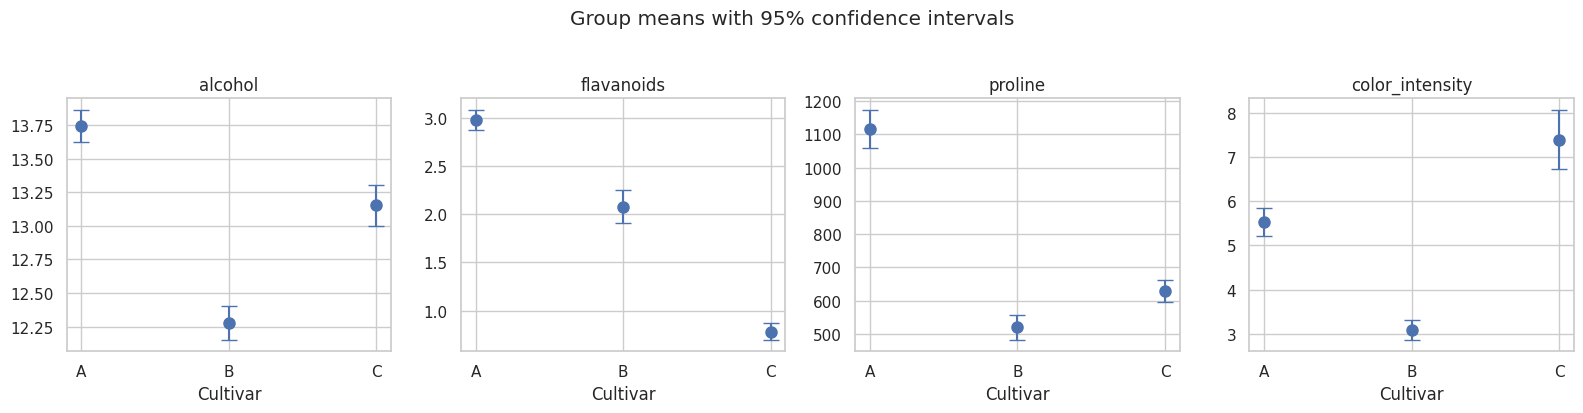

In [18]:
fig, axes = plt.subplots(1, len(VARS), figsize=(16, 4))
for ax, var in zip(axes, VARS):
    d = ci_tbl[ci_tbl.variable == var]
    ax.errorbar(d["group"].str[-1], d["mean"],
                yerr=[d["mean"] - d["ci95_low"], d["ci95_high"] - d["mean"]],
                fmt="o", capsize=6, markersize=8)
    ax.set_title(var); ax.set_xlabel("Cultivar")
plt.suptitle("Group means with 95% confidence intervals", y=1.03)
plt.tight_layout(); plt.show()


## 7 · Findings & interpretation

**Normality (Shapiro-Wilk + Lilliefors K-S)**
- Cultivar A is normal for all four variables. Cultivar B and C deviate from normality for several variables (e.g. flavanoids, B: Shapiro p = 0.0015; C: p = 0.0004; color intensity B: p = 0.0008).
- Alcohol in Cultivar B is borderline (Shapiro p = 0.114 but K-S p = 0.048), so it was conservatively flagged non-normal.
- Because normality fails for at least one group in every variable, the **Mann-Whitney U / Kruskal-Wallis results are the primary evidence**, with the t-test / ANOVA as parametric confirmation.

**Two-sample tests (A vs B)**
- All four variables show a significant difference (Mann-Whitney p < 10⁻¹³; Welch t-test agrees). H₀ is rejected in every case.
- Effect sizes are very large (Cohen's *d* from 1.5 for flavanoids to 3.2 for proline). Example: Cultivar A has on average **1.47 % vol. more alcohol** than B (95 % CI 1.29 – 1.64) and **596 mg/L more proline** (95 % CI 528 – 664).

**One-Way ANOVA + Tukey HSD**
- Cultivar has a significant effect on all four variables (ANOVA and Kruskal-Wallis p < 0.0001); η² ranges from 0.58 to 0.73, i.e. cultivar explains well over half of the variance.
- Tukey HSD shows **every pairwise cultivar comparison is significant** for all four variables (the closest, proline B vs C, still has adjusted p = 0.002).
- Levene's test shows unequal variances for flavanoids, proline and color intensity. With such large effects the conclusions do not change, and Kruskal-Wallis gives the same answer.

**Two-Way ANOVA (flavanoids ~ cultivar × alcohol level)**
- **Cultivar:** highly significant (F = 128.7, p < 0.0001, partial η² = 0.60).
- **Alcohol level:** not significant (p = 0.19) — once cultivar is accounted for, high- vs low-alcohol wines do not differ in flavanoids.
- **Interaction:** not significant (p = 0.58); the lines in the interaction plot are roughly parallel.
- **Caveats:** the design is strongly unbalanced (e.g. 53 High vs 6 Low in Cultivar A; 5 High vs 66 Low in B), which is why Type III sums of squares were used. Residuals are non-normal and variances unequal across cells, so p-values should be read as indicative; the cultivar effect is large enough that the conclusion is safe.

**Overall conclusion:** the three wine cultivars are chemically distinct on alcohol, flavanoids, proline and color intensity, and cultivar is by far the dominant factor. Alcohol level adds no explanatory power for flavanoids beyond cultivar.
